# 08 — Synoptic overview of the February 2022 winter storm (GFS analyses)

Produces the single 2 × 2 synoptic figure used in the manuscript, from GFS 0.25° analyses (f000) at four times:
1 Feb 00 UTC, 2 Feb 00 UTC, 3 Feb 18 UTC (case-study time) and 4 Feb 18 UTC.

**Each panel shows**
- **IVT magnitude** (1000–300 hPa), shaded;
- **500-hPa geopotential height** (m), black contours every 60 m;
- **850-hPa temperature**, thin dashed isotherms every 4 °C (blue < 0 °C, red > 0 °C);
- **850-hPa 0 °C** (magenta) and **2-m 0 °C** (cyan) lines.

**Changes in response to the reviewer**
1. **IVT colour ramp.** `viridis` (dark purple at the lowest values) is replaced by a sequential ramp that starts near white (`YlGn`). Low IVT is now pale, so the overlaid lines stay readable, and the shading fades smoothly into the unshaded area below 50 kg m⁻¹ s⁻¹ instead of jumping from white to dark purple.
2. **Line hierarchy.** State outlines are thin and light grey, country borders and coastlines slightly darker, and 500-hPa heights clearly thicker and black, so the two are easy to tell apart. The isotherms are thinner and dashed. The two freezing lines are the thickest and carry a thin dark outline, so they stand out on every shade.
3. **Clutter.** The inline freezing-line labels are replaced by a single legend, and the colour bar sits below all four panels.

Only the code needed for this figure is kept; the exploratory plots and the unused functions from the original notebook were removed.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 2. Configuration

In [2]:
# GFS 0.25° analyses (f000), one per panel
GFS_FILES = {
    pd.Timestamp("2022-02-01 00:00"): "/glade/work/sakor/gfs/gfs.0p25.2022020100.f000.grib2",
    pd.Timestamp("2022-02-02 00:00"): "/glade/work/sakor/gfs/gfs.0p25.2022020200.f000.grib2",
    pd.Timestamp("2022-02-03 18:00"): "/glade/work/sakor/gfs/gfs.0p25.2022020318.f000.grib2",
    pd.Timestamp("2022-02-04 18:00"): "/glade/work/sakor/gfs/gfs.0p25.2022020418.f000.grib2",
}
FIG = Path("/glade/work/sakor/AI_NWP/figures_modal")
FIG.mkdir(parents=True, exist_ok=True)
FIG_NAME = "synoptic_ivt_feb2022"

# domain
EXTENT = [-120, -75, 26, 50]
SUBSET = dict(lat=(20, 56), lon=(-130, -65))      # read slightly larger than the map
PROJ = ccrs.LambertConformal(central_longitude=-97.5, standard_parallels=(38.5, 38.5))

# IVT
IVT_PTOP, IVT_PBOT = 300, 1000                     # hPa
IVT_LEVELS = np.arange(50, 1201, 50)               # kg m-1 s-1; below 50 is unshaded
IVT_CMAP = ListedColormap(plt.get_cmap("YlGn")(np.linspace(0.0, 0.92, len(IVT_LEVELS) - 1)))
IVT_CMAP.set_over(plt.get_cmap("YlGn")(1.0))
IVT_TICKS = np.arange(100, 1201, 100)

# contours
Z500_INTERVAL = 60                                  # m
T850_COLD = np.arange(-20, 0, 4)                    # °C
T850_WARM = np.arange(4, 25, 4)

# line styles (reviewer: distinct widths for states vs heights)
STYLE = {
    "states":   dict(linewidth=0.35, edgecolor="0.55"),
    "borders":  dict(linewidth=0.6,  edgecolor="0.35"),
    "coast":    dict(linewidth=0.6,  edgecolor="0.35"),
    "z500":     dict(colors="black", linewidths=1.3),
    "t850_cold": dict(colors="#2166ac", linewidths=0.8, linestyles="--"),
    "t850_warm": dict(colors="#b2182b", linewidths=0.8, linestyles="--"),
    "t850_0":   dict(colors="magenta", linewidths=2.2),
    "t2m_0":    dict(colors="cyan", linewidths=2.2),
}
HALO = [pe.Stroke(linewidth=3.4, foreground="0.15"), pe.Normal()]   # dark outline for freezing lines
DRAW_FEATURES = True

plt.rcParams.update({"font.family": "sans-serif", "font.size": 9,
                     "pdf.fonttype": 42, "ps.fonttype": 42})

## 3. Reading GFS and computing IVT

- Pressure-level fields (`u`, `v`, `q`, `t`, `gh`) and the 2-m temperature are read from the same GRIB2 file with cfgrib.
- Longitudes are converted to −180…180 and the domain is cropped before any computation.
- **IVT** = (1/g) ∫ q **V** dp from 1000 to 300 hPa (trapezoidal rule), the standard definition; only the magnitude is plotted.

In [3]:
G = 9.80665

def _tidy(ds):
    if float(ds.longitude.max()) > 180:
        ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    ds = ds.sortby("latitude")
    return ds.sel(latitude=slice(*SUBSET["lat"]), longitude=slice(*SUBSET["lon"]))

def open_pressure_levels(path):
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={
        "filter_by_keys": {"typeOfLevel": "isobaricInhPa"}, "indexpath": ""})
    if "q" not in ds and "sh" in ds:
        ds = ds.rename(sh="q")
    missing = [v for v in ("u", "v", "q", "t", "gh") if v not in ds]
    if missing:
        raise KeyError(f"{path}: missing {missing}; found {list(ds.data_vars)}")
    return _tidy(ds[["u", "v", "q", "t", "gh"]])

def open_t2m(path):
    ds = xr.open_dataset(path, engine="cfgrib", backend_kwargs={
        "filter_by_keys": {"typeOfLevel": "heightAboveGround", "level": 2, "shortName": "2t"},
        "indexpath": ""})
    return _tidy(ds)[list(ds.data_vars)[0]].squeeze(drop=True) - 273.15

def ivt_magnitude(ds, ptop=IVT_PTOP, pbot=IVT_PBOT):
    lay = ds.sel(isobaricInhPa=slice(None)).where(
        (ds.isobaricInhPa >= ptop) & (ds.isobaricInhPa <= pbot), drop=True)
    lay = lay.sortby("isobaricInhPa")                       # ascending p -> positive integral
    lay = lay.assign_coords(p_pa=("isobaricInhPa", lay.isobaricInhPa.values * 100.0))
    lay = lay.swap_dims(isobaricInhPa="p_pa")
    ivt_u = (lay.q * lay.u).integrate("p_pa") / G
    ivt_v = (lay.q * lay.v).integrate("p_pa") / G
    out = np.hypot(ivt_u, ivt_v).squeeze(drop=True)
    out.attrs["units"] = "kg m-1 s-1"
    return out

## 4. Load the four analyses

In [4]:
fields = {}
for t, path in GFS_FILES.items():
    pl = open_pressure_levels(path)
    fields[t] = {
        "ivt": ivt_magnitude(pl),
        "z500": pl.gh.sel(isobaricInhPa=500).squeeze(drop=True),
        "t850": pl.t.sel(isobaricInhPa=850).squeeze(drop=True) - 273.15,
        "t2m": open_t2m(path),
    }
    f = fields[t]
    print(f"{t:%Y-%m-%d %H}Z  IVT max {float(f['ivt'].max()):6.0f} kg/m/s | "
          f"Z500 {float(f['z500'].min()):.0f}–{float(f['z500'].max()):.0f} m | "
          f"T850 {float(f['t850'].min()):.1f}–{float(f['t850'].max()):.1f} °C")

skipping variable: paramId==228164 shortName='tcc'
Traceback (most recent call last):
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  250.,
        200.,  150.,  100.,   70.,   50.,   40.,   30.,   20.,   15.,
         10.,    7.,    5.,    3.,    2.,    1.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  25

2022-02-01 00Z  IVT max    770 kg/m/s | Z500 5087–5839 m | T850 -28.7–26.7 °C


skipping variable: paramId==228164 shortName='tcc'
Traceback (most recent call last):
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  250.,
        200.,  150.,  100.,   70.,   50.,   40.,   30.,   20.,   15.,
         10.,    7.,    5.,    3.,    2.,    1.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  25

2022-02-02 00Z  IVT max    613 kg/m/s | Z500 5039–5837 m | T850 -33.3–26.4 °C


skipping variable: paramId==228164 shortName='tcc'
Traceback (most recent call last):
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  250.,
        200.,  150.,  100.,   70.,   50.,   40.,   30.,   20.,   15.,
         10.,    7.,    5.,    3.,    2.,    1.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  25

2022-02-03 18Z  IVT max   1117 kg/m/s | Z500 4923–5873 m | T850 -35.7–25.6 °C


skipping variable: paramId==228164 shortName='tcc'
Traceback (most recent call last):
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
  File "/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='isobaricInhPa' value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  250.,
        200.,  150.,  100.,   70.,   50.,   40.,   30.,   20.,   15.,
         10.,    7.,    5.,    3.,    2.,    1.])) new_value=Variable(dimensions=('isobaricInhPa',), data=array([1000.,  975.,  950.,  925.,  900.,  850.,  800.,  750.,  700.,
        650.,  600.,  550.,  500.,  450.,  400.,  350.,  300.,  25

2022-02-04 18Z  IVT max   1265 kg/m/s | Z500 5024–5893 m | T850 -29.3–23.8 °C


## 5. Figure

2 × 2 panels, one colour bar and one line legend below the panels. Saved as PDF and PNG.

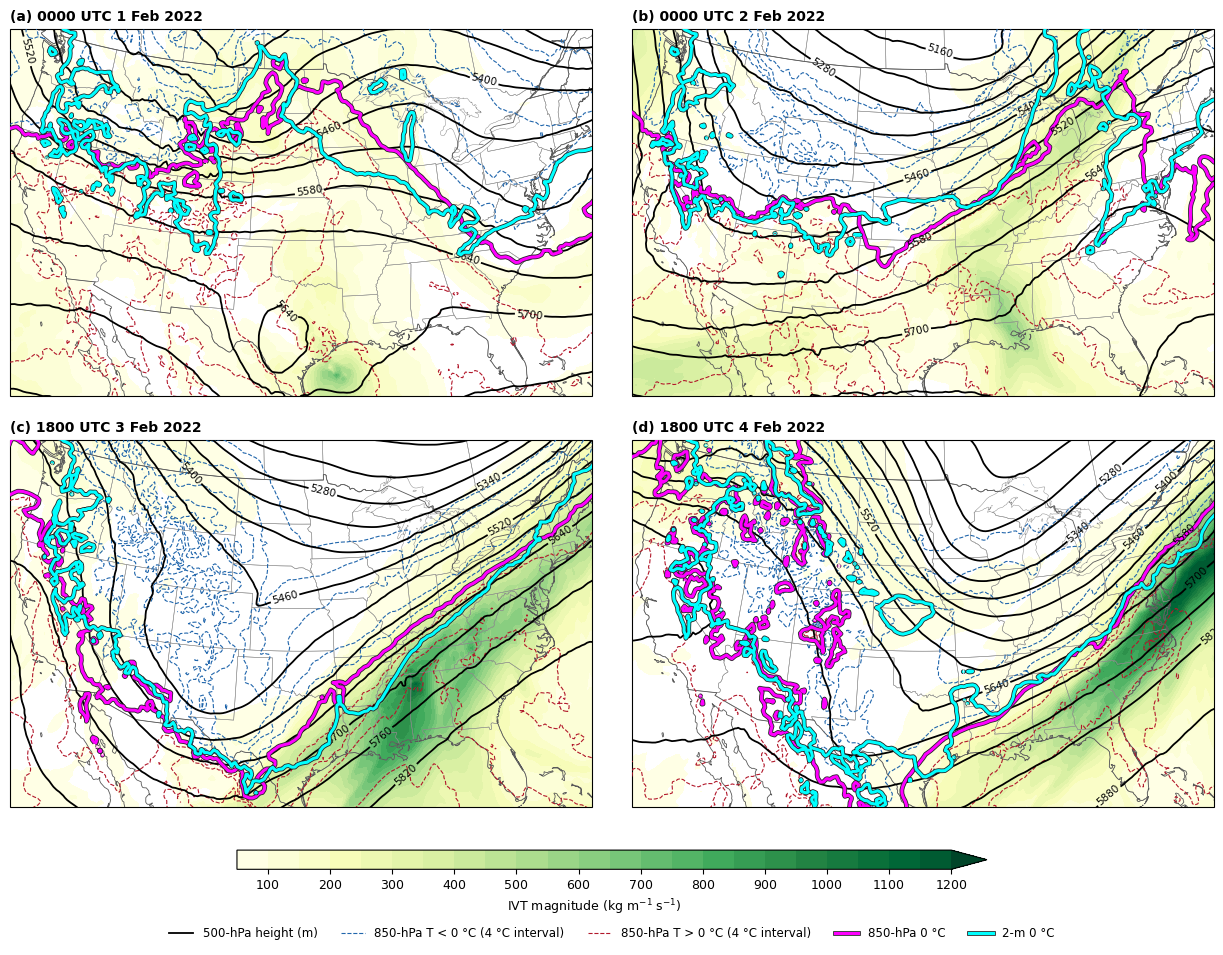

Saved /glade/work/sakor/AI_NWP/figures_modal/synoptic_ivt_feb2022.pdf


In [5]:
def add_map_features(ax):
    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    if not DRAW_FEATURES:
        return
    ax.add_feature(cfeature.STATES.with_scale("50m"), facecolor="none", **STYLE["states"], zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), **STYLE["borders"], zorder=2)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), **STYLE["coast"], zorder=2)

def draw_panel(ax, f, title):
    pc = ccrs.PlateCarree()
    add_map_features(ax)

    ivt = f["ivt"]
    cf = ax.contourf(ivt.longitude, ivt.latitude, ivt, levels=IVT_LEVELS, cmap=IVT_CMAP,
                     extend="max", transform=pc, zorder=1)

    t850 = f["t850"]
    ax.contour(t850.longitude, t850.latitude, t850, levels=T850_COLD, transform=pc, zorder=3,
               **STYLE["t850_cold"])
    ax.contour(t850.longitude, t850.latitude, t850, levels=T850_WARM, transform=pc, zorder=3,
               **STYLE["t850_warm"])

    z = f["z500"]
    zl = np.arange(np.floor(float(z.min()) / Z500_INTERVAL) * Z500_INTERVAL,
                   float(z.max()) + Z500_INTERVAL, Z500_INTERVAL)
    cz = ax.contour(z.longitude, z.latitude, z, levels=zl, transform=pc, zorder=4, **STYLE["z500"])
    for lab in ax.clabel(cz, fmt=lambda x: f"{int(x)}", fontsize=7.5, inline=True, inline_spacing=2):
        lab.set_clip_path(ax.patch)

    c850 = ax.contour(t850.longitude, t850.latitude, t850, levels=[0], transform=pc, zorder=5,
                      **STYLE["t850_0"])
    t2m = f["t2m"]
    c2m = ax.contour(t2m.longitude, t2m.latitude, t2m, levels=[0], transform=pc, zorder=6,
                     **STYLE["t2m_0"])
    for cs in (c850, c2m):
        for coll in getattr(cs, "collections", [cs]):
            coll.set_path_effects(HALO)

    ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
    return cf

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.6), subplot_kw={"projection": PROJ})
fig.subplots_adjust(left=0.01, right=0.99, top=0.96, bottom=0.15, wspace=0.03, hspace=0.12)
for k, (ax, (t, f)) in enumerate(zip(axes.ravel(), fields.items())):
    cf = draw_panel(ax, f, f"({'abcd'[k]}) {t:%H%M} UTC {t.day} Feb 2022")

cax = fig.add_axes([0.2, 0.085, 0.6, 0.02])
cb = fig.colorbar(cf, cax=cax, orientation="horizontal", ticks=IVT_TICKS, extend="max")
cb.set_label("IVT magnitude (kg m$^{-1}$ s$^{-1}$)")

halo_line = lambda c: Line2D([], [], color=c, lw=2.2, path_effects=HALO)
handles = [
    Line2D([], [], color="black", lw=1.3, label="500-hPa height (m)"),
    Line2D([], [], color="#2166ac", lw=0.8, ls="--", label="850-hPa T < 0 °C (4 °C interval)"),
    Line2D([], [], color="#b2182b", lw=0.8, ls="--", label="850-hPa T > 0 °C (4 °C interval)"),
]
h850, h2m = halo_line("magenta"), halo_line("cyan")
h850.set_label("850-hPa 0 °C")
h2m.set_label("2-m 0 °C")
fig.legend(handles=handles + [h850, h2m], loc="lower center", ncol=5, frameon=False,
           fontsize=8.5, bbox_to_anchor=(0.5, 0.0))

fig.savefig(FIG / f"{FIG_NAME}.pdf", bbox_inches="tight", dpi=300)
fig.savefig(FIG / f"{FIG_NAME}.png", bbox_inches="tight", dpi=200)
plt.show()
print(f"Saved {FIG / (FIG_NAME + '.pdf')}")


> GFS analyses at (a) 0000 UTC 1 February, (b) 0000 UTC 2 February, (c) 1800 UTC 3 February, and (d) 1800 UTC 4 February 2022. Shading shows the magnitude of integrated vapor transport (IVT, 1000–300 hPa; values below 50 kg m⁻¹ s⁻¹ unshaded). Black contours show 500-hPa geopotential height (m, every 60 m), and thin dashed contours show 850-hPa temperature every 4 °C (blue below and red above 0 °C). Magenta and cyan lines mark the 850-hPa and 2-m 0 °C isotherms.